# STATIONARITY + ADF + DIFFERENCING

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [2]:
df = pd.read_csv("Rossman_store.csv")

C:\Users\kashr\AppData\Local\Temp\ipykernel_10904\2326356240.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Rossman_store.csv")


In [3]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [4]:
df = pd.read_csv("Rossman_store.csv")

C:\Users\kashr\AppData\Local\Temp\ipykernel_10904\2326356240.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Rossman_store.csv")


In [5]:
df.shape

(1017209, 9)

In [6]:
# Select Store 800
store_800 = df[df["Store"] == 800].copy()

# Convert Date to datetime
store_800["Date"] = pd.to_datetime(store_800["Date"])

# Sort chronologically and set Date as the index
store_800 = store_800.sort_values("Date")
store_800 = store_800.set_index("Date")

# Keep the daily Sales series
sales = store_800["Sales"].asfreq("D")

print("Observations:", len(sales))
print("Start date:", sales.index.min())
print("End date:", sales.index.max())
print("Missing sales values:", sales.isna().sum())

Observations: 942
Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00
Missing sales values: 0


In [7]:
# Forecast horizon: final 42 days
horizon = 42

train = sales.iloc[:-horizon]
test = sales.iloc[-horizon:]

print("Training observations:", len(train))
print("Test observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())

Training observations: 900
Test observations: 42
Training period: 2013-01-01 00:00:00 to 2015-06-19 00:00:00
Test period: 2015-06-20 00:00:00 to 2015-07-31 00:00:00


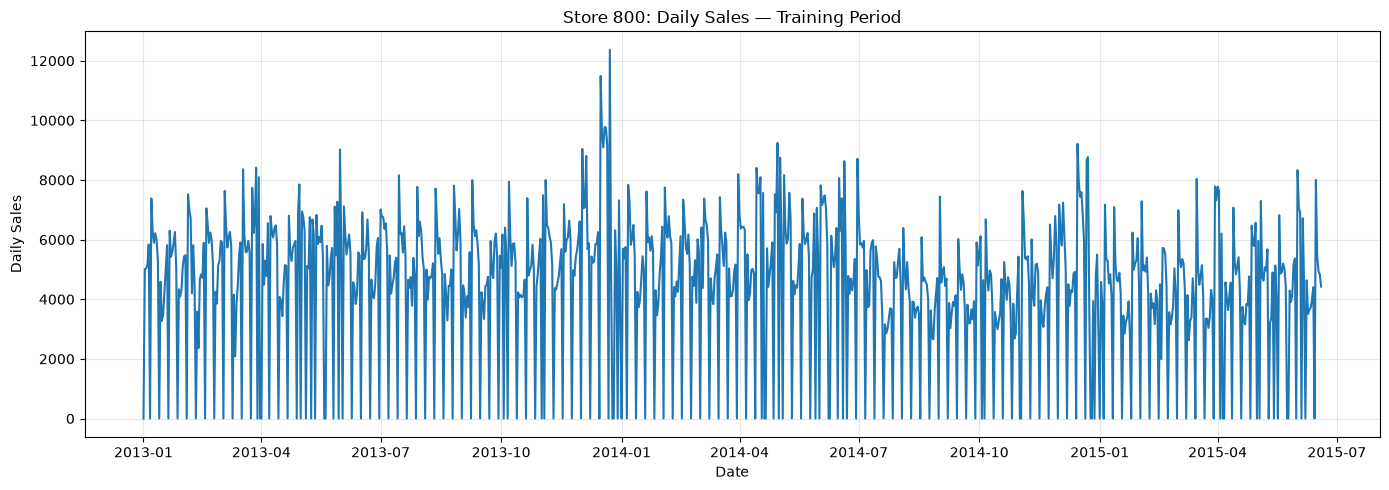

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values)
plt.title("Store 800: Daily Sales — Training Period")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ADF TESTING

In [9]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(train.dropna())

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])

ADF Statistic: -3.761761067802677
p-value: 0.003323694807797099
Critical Values: {'1%': np.float64(-3.437819842246547), '5%': np.float64(-2.8648374649929753), '10%': np.float64(-2.5685258078777093)}


In [10]:
!pip install pmdarima

In [11]:
import pmdarima as pm

In [12]:
d = pm.arima.ndiffs(train.dropna(), test="adf")
print("Suggested ordinary differencing order (d):", d)

Suggested ordinary differencing order (d): 0


In [13]:
D = pm.arima.nsdiffs(train.dropna(), m=7, test="ocsb")
print("Suggested seasonal differencing order (D):", D)

Suggested seasonal differencing order (D): 0


In [14]:
from statsmodels.tsa.stattools import adfuller

# First-order differencing
train_diff = train.diff().dropna()

# Run the second ADF test
adf_result_2 = adfuller(train_diff)

print("Second ADF Test Results")
print("ADF Statistic:", adf_result_2[0])
print("p-value:", adf_result_2[1])
print("Lags Used:", adf_result_2[2])
print("Observations Used:", adf_result_2[3])

print("\nCritical Values:")
for key, value in adf_result_2[4].items():
    print(f"{key}: {value}")

if adf_result_2[1] < 0.05:
    print("\nConclusion: Reject the unit-root null hypothesis.")
    print("The differenced series is stationary according to the ADF test.")
else:
    print("\nConclusion: Fail to reject the unit-root null hypothesis.")
    print("The differenced series is not confirmed stationary by the ADF test.")

Second ADF Test Results
ADF Statistic: -11.802328244825109
p-value: 9.267704952337237e-22
Lags Used: 21
Observations Used: 877

Critical Values:
1%: -3.4378283848659277
5%: -2.864841231335243
10%: -2.5685278140988053

Conclusion: Reject the unit-root null hypothesis.
The differenced series is stationary according to the ADF test.


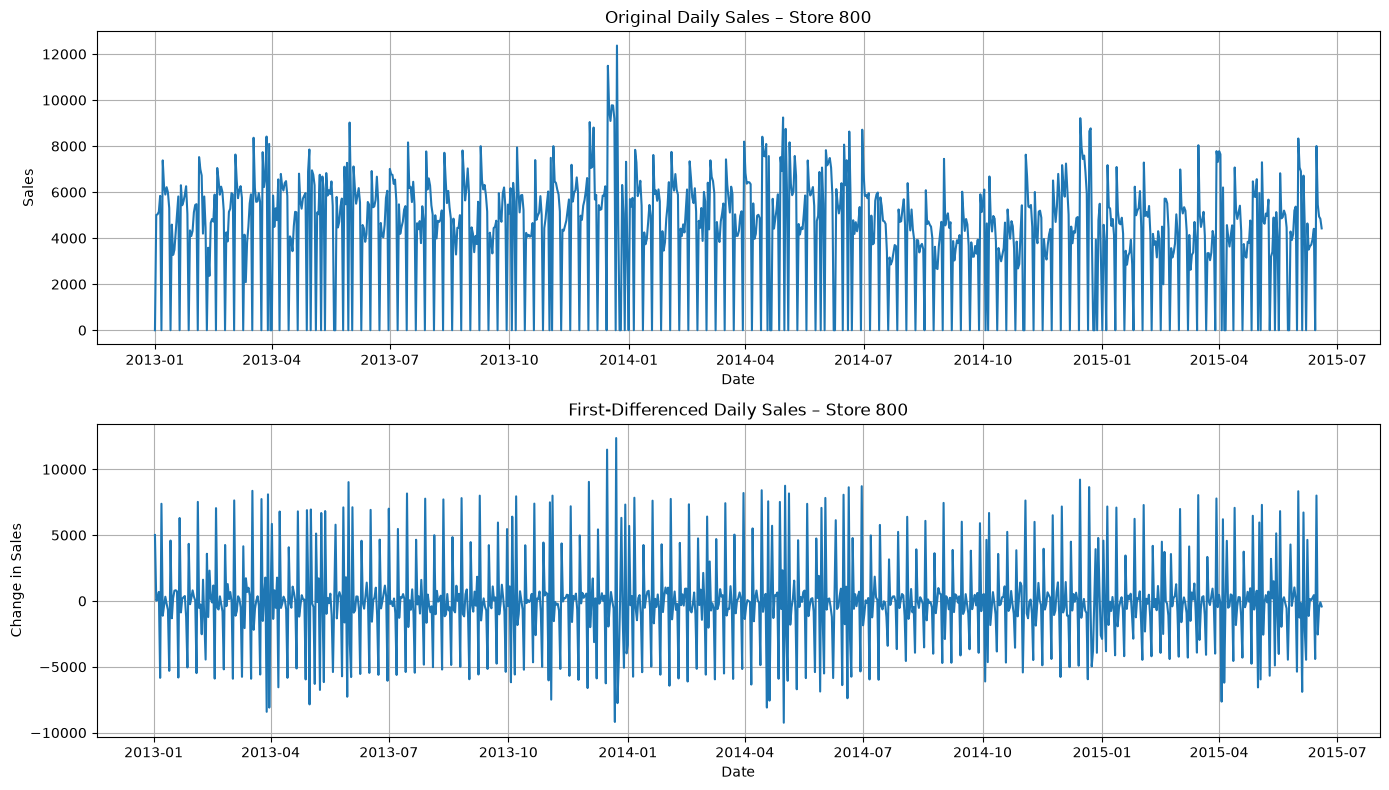

In [15]:
import matplotlib.pyplot as plt

# Plot original and differenced sales series
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Original sales series
axes[0].plot(train.index, train)
axes[0].set_title("Original Daily Sales – Store 800")
axes[0].set_ylabel("Sales")
axes[0].set_xlabel("Date")
axes[0].grid(True)

# First-differenced sales series
axes[1].plot(train_diff.index, train_diff)
axes[1].set_title("First-Differenced Daily Sales – Store 800")
axes[1].set_ylabel("Change in Sales")
axes[1].set_xlabel("Date")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Key Findings and Conclusion: Stationarity, ADF and Differencing

## 1. Original Series: ADF Test

The original Store 800 training series contained 900 daily observations.

- **ADF statistic:** −3.7618
- **p-value:** 0.003323
- **Lags used:** 21
- **Observations used:** 878
- **5% critical value:** −2.8648

**Finding:** The p-value was below 0.05, so the unit-root null hypothesis was rejected. The result provides evidence against a unit root in the original series.

## 2. First-Differenced Series: ADF Test

First-order differencing was applied to calculate day-to-day changes in sales.

- **ADF statistic:** −11.8023
- **p-value:** 9.2677 × 10⁻²²
- **Lags used:** 21
- **Observations used:** 877
- **5% critical value:** −2.8648

**Finding:** The unit-root null hypothesis was also rejected for the differenced series.

## 3. Differencing and Visual Assessment

The `pmdarima` procedures recommended:

- Ordinary differencing: **d = 0**
- Seasonal differencing: **D = 0**
- Weekly seasonal period: **m = 7**

The plots compare the original sales levels with day-to-day changes in sales. The differenced series provides a different view of sales fluctuations, while visual inspection alone cannot establish stationarity.

## 4. Overall Conclusion and Handoff

The original series provided evidence against a unit root, and the selected differencing procedures recommended no ordinary or seasonal differencing. The first-differenced series was also found to provide evidence against a unit root, but differencing was not indicated as necessary for the original series.

# ACF, PACF and Model Identification

Objective

This section investigates the autocorrelation structure of Store 800 daily sales to identify potential ARIMA/SARIMA model orders. It follows the stationarity analysis and differencing recommendations from the previous section.

The original training series is examined first because the ADF test rejected the unit-root null hypothesis and the differencing procedures recommended (d=0) and (D=0). The first-differenced series is also available for comparison.

The ACF and PACF plots will be used to identify important lags and suggest candidate model structures. These plots guide model selection but do not determine the final model on their own.

In [16]:
print(train.head())
print(type(train))
print(train.name)

Date
2013-01-01       0
2013-01-02    5009
2013-01-03    5034
2013-01-04    5150
2013-01-05    5836
Freq: D, Name: Sales, dtype: int64
<class 'pandas.Series'>
Sales


In [17]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# original sales series ACF and PACF

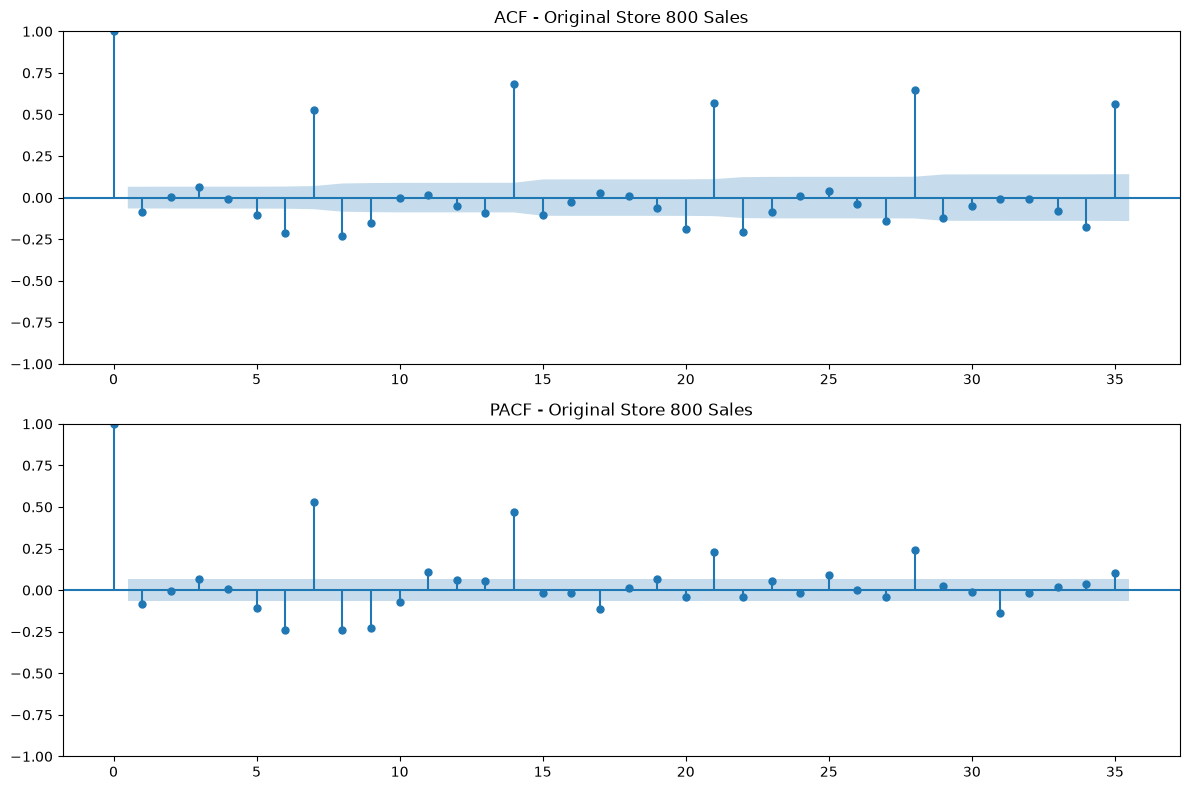

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train.dropna(), lags=35, ax=axes[0])
axes[0].set_title("ACF - Original Store 800 Sales")

plot_pacf(train.dropna(), lags=35, method="ywm", ax=axes[1])
axes[1].set_title("PACF - Original Store 800 Sales")

plt.tight_layout()
plt.show()

# ACF & PACF First Differenced 

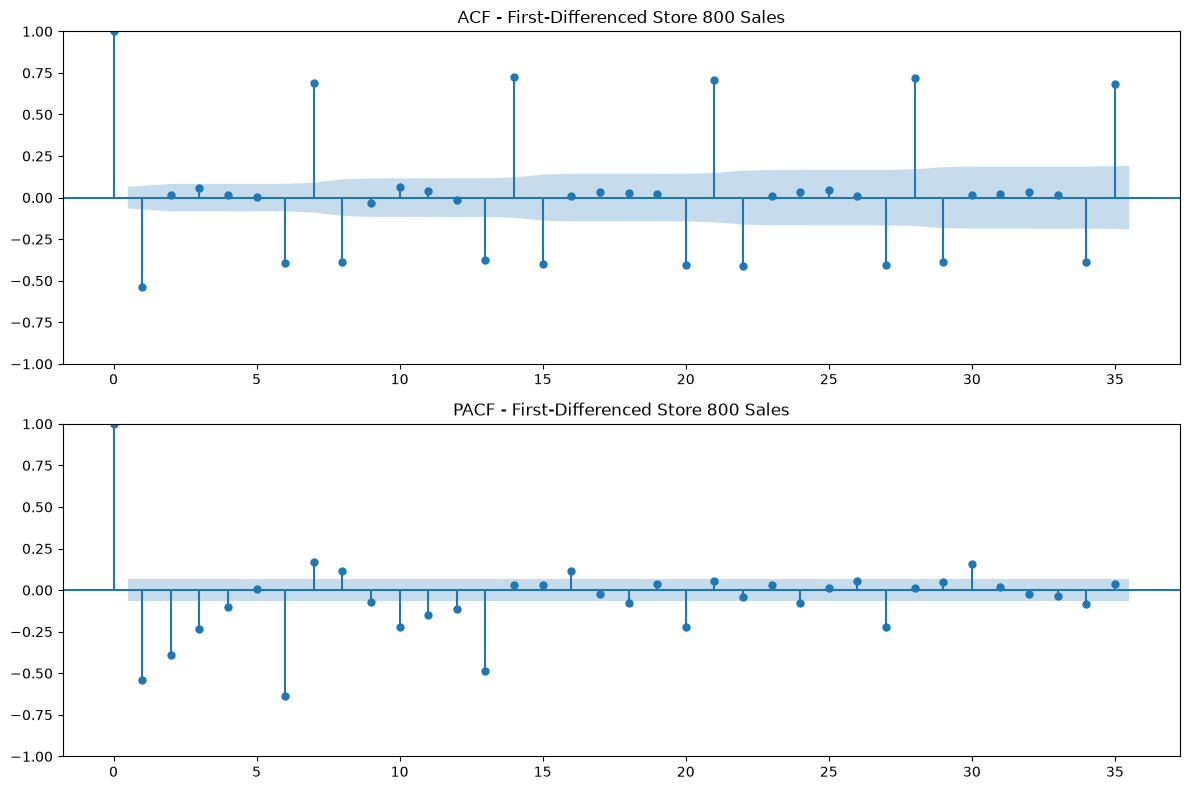

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train_diff.dropna(), lags=35, ax=axes[0])
axes[0].set_title("ACF - First-Differenced Store 800 Sales")

plot_pacf(train_diff.dropna(), lags=35, method="ywm", ax=axes[1])
axes[1].set_title("PACF - First-Differenced Store 800 Sales")

plt.tight_layout()
plt.show()

## Automatic ARIMA Model Identification

In [30]:

model = pm.auto_arima(
    train,
    seasonal=True,
    m=7,
    suppress_warnings=True,
    stepwise=True,
    trace=True
)

print(model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=inf, Time=4.16 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=17236.098, Time=0.03 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=16380.984, Time=0.72 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=inf, Time=0.99 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=17234.100, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[7] intercept   : AIC=16928.509, Time=0.07 sec
 ARIMA(1,1,0)(2,0,0)[7] intercept   : AIC=16114.999, Time=1.37 sec
 ARIMA(1,1,0)(2,0,1)[7] intercept   : AIC=16187.008, Time=2.56 sec
 ARIMA(1,1,0)(1,0,1)[7] intercept   : AIC=16182.456, Time=2.08 sec
 ARIMA(0,1,0)(2,0,0)[7] intercept   : AIC=16410.751, Time=1.32 sec
 ARIMA(2,1,0)(2,0,0)[7] intercept   : AIC=16028.267, Time=1.84 sec
 ARIMA(2,1,0)(1,0,0)[7] intercept   : AIC=16332.880, Time=0.98 sec
 ARIMA(2,1,0)(2,0,1)[7] intercept   : AIC=16118.254, Time=3.51 sec
 ARIMA(2,1,0)(1,0,1)[7] intercept   : AIC=16098.187, Time=2.66 sec
 ARIMA(3,1,0)(2,0,0)[7] interce

In [31]:
print("ARIMA order:", model.order)
print("Seasonal order:", model.seasonal_order)

forecast = model.predict(n_periods=len(test))

print("Forecast length:", len(forecast))
print(forecast[:5])

ARIMA order: (5, 1, 0)
Seasonal order: (2, 0, 0, 7)
Forecast length: 42
2015-06-20    5013.793233
2015-06-21    1304.549563
2015-06-22    5508.059784
2015-06-23    4637.469540
2015-06-24    4613.804443
Freq: D, dtype: float64


### MAE & RMSE Evaluation

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 1187.0671926387665
RMSE: 1431.2908183577345


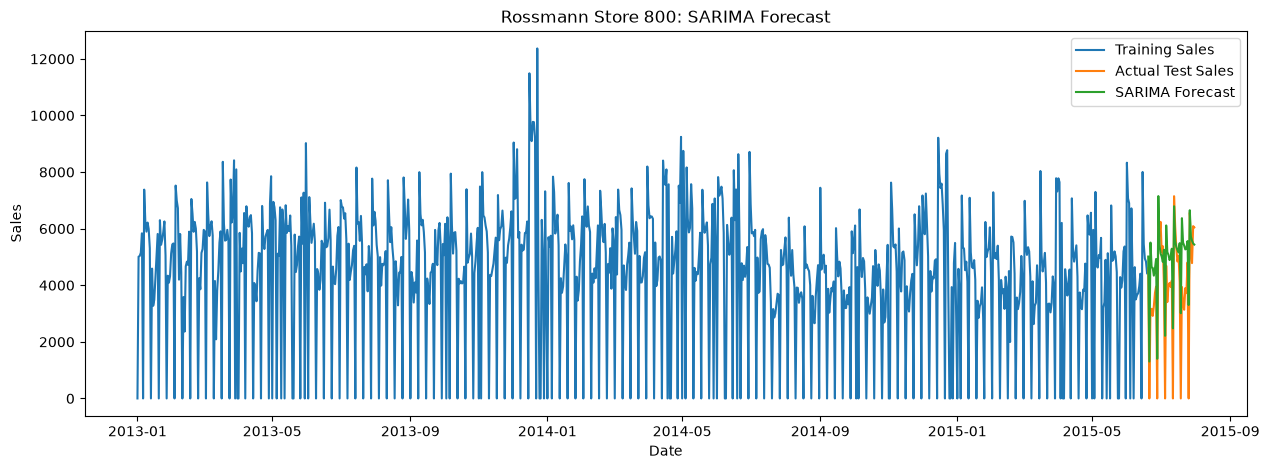

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(train.index, train, label="Training Sales")
plt.plot(test.index, test, label="Actual Test Sales")
plt.plot(test.index, forecast, label="SARIMA Forecast")

plt.title("Rossmann Store 800: SARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

# Key Findings and Conclusion

## 1. Stationarity Analysis

The Augmented Dickey-Fuller (ADF) test on the original training sales data gave a test statistic of -3.7618 and a p-value of 0.0033. Since the p-value was below 0.05, we rejected the null hypothesis of a unit root. This provided evidence against a unit root in the original sales series.

The `pmdarima` tests recommended no ordinary or seasonal differencing (d = 0, D = 0). However, Auto ARIMA selected a model with one order of ordinary differencing (d = 1). We kept this difference in mind when evaluating the selected model.

## 2. ACF and PACF Analysis

The original ACF plot showed strong positive autocorrelation at lags 7, 14, 21, 28 and 35. This suggests that Store 800 sales follow a weekly pattern, with sales related to those recorded on the corresponding days of previous weeks.

The first-differenced ACF still showed noticeable spikes at weekly lags, while lag 1 became negative. The PACF plots also showed prominent early-lag effects and spikes at seasonal lags, including lags 7 and 14 in the original series.

These patterns helped us identify possible autoregressive and seasonal autoregressive terms. However, the plots did not give us one clear model order, so we also used Auto ARIMA to compare candidate models.

## 3. Model Identification and Alternative Models

Auto ARIMA selected SARIMA(5,1,0)(2,0,0)[7], with an AIC of 16,006.271. The model uses five non-seasonal autoregressive terms, one order of ordinary differencing, two seasonal autoregressive terms and a seasonal period of seven days.

Other models considered during the search included:

- SARIMA(4,1,0)(2,0,0)[7], with an AIC of 16,014.084.
- SARIMA(3,1,0)(2,0,0)[7], with an AIC of 16,024.362.
- SARIMA(2,1,0)(2,0,0)[7], with an AIC of 16,028.267.

These alternatives had higher AIC values than the selected model, so Auto ARIMA preferred SARIMA(5,1,0)(2,0,0)[7] among these candidates. However, AIC alone does not tell us which model will produce the most accurate forecasts on unseen data.

## 4. Forecast Evaluation

We fitted the selected SARIMA model using 900 training observations and evaluated it on the final 42 days of the dataset. The model achieved an MAE of 1,187.07 and an RMSE of 1,431.29.

We also plotted the actual test-period sales against the forecast to compare the predictions with the observed sales.

## 5. Comparing SARIMA with the Baseline Models

After comparing the results, we found that Seasonal Naive and SARIMA performed better than the other baseline models, although each had a different strength.

The Seasonal Naive model recorded an MAE of 1,004.83, which was lower than SARIMA's 1,187.07. This means that, on average, Seasonal Naive made smaller absolute errors. However, SARIMA had a lower RMSE of 1,431.29 compared with 1,479.89 for Seasonal Naive, suggesting that it performed slightly better when larger forecasting errors were taken into account.

The other baseline models performed less well. Naive recorded an MAE of 1,449.17 and an RMSE of 1,976.13, while Drift recorded 1,450.92 and 1,993.41 respectively. Moving Average had the highest errors, with an MAE of 1,471.68 and an RMSE of 2,019.25.

Overall, SARIMA did not perform better on every metric. Seasonal Naive had the lower MAE, while SARIMA had the lower RMSE. Both models therefore need further consideration before we make a final recommendation.

## 6. Overall Conclusion and Next Steps

From the results so far, we saw that Store 800 sales follow a weekly pattern. When we compared the models, Seasonal Naive gave a lower MAE, while SARIMA had a lower RMSE. This shows that the more advanced model did not perform better in every area.

We don't want to choose a final model based on these results alone. We still need to check the SARIMA residuals and test both models across different periods to see if their performance stays consistent.

After these checks, we will be in a better position to decide which model is more suitable for forecasting sales for the next six weeks.

# Forcasting and Model Evaluation 

In [38]:
print("Store 800 observations:", len(store_800))
print("First date:", store_800.index.min())
print("Last date:", store_800.index.max())
print(store_800.tail())

Store 800 observations: 942
First date: 2013-01-01 00:00:00
Last date: 2015-07-31 00:00:00
            Store  DayOfWeek  Sales  Customers  Open  Promo StateHoliday  \
Date                                                                       
2015-07-27    800          1   6566        546     1      1            0   
2015-07-28    800          2   5174        435     1      1            0   
2015-07-29    800          3   4783        427     1      1            0   
2015-07-30    800          4   6089        496     1      1            0   
2015-07-31    800          5   6045        507     1      1            0   

            SchoolHoliday  
Date                       
2015-07-27              1  
2015-07-28              1  
2015-07-29              1  
2015-07-30              1  
2015-07-31              1  


### Residual code

In [40]:
# Extract residuals from the evaluated SARIMA model

residuals = model.resid()

print("Number of residuals:", len(residuals))
print(residuals[:5])

Number of residuals: 900
Date
2013-01-01       0.000000
2013-01-02    5009.000000
2013-01-03    3283.271194
2013-01-04    1790.670183
2013-01-05    1718.425194
Freq: D, dtype: float64


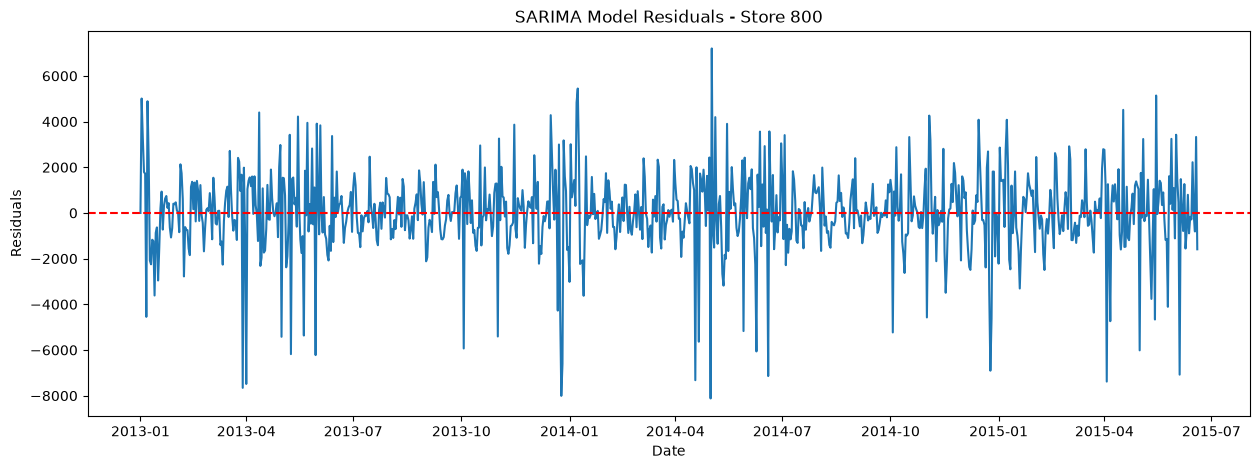

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(residuals)
plt.axhline(y=0, color="red", linestyle="--")
plt.title("SARIMA Model Residuals - Store 800")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.show()

### Residual autocorrelation 

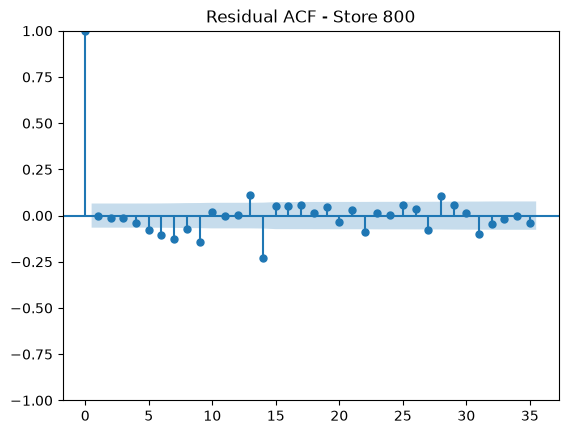

In [43]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residuals, lags=35)
plt.title("Residual ACF - Store 800")
plt.show()

#### Ljung Box-Test

In [44]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_result = acorr_ljungbox(
    residuals,
    lags=[7, 14, 21, 28],
    return_df=True
)

print(ljung_box_result)

       lb_stat     lb_pvalue
7    32.414005  3.403048e-05
14  116.902986  2.537520e-18
21  129.106200  1.488165e-17
28  157.262940  5.976954e-20


### Residual normality check

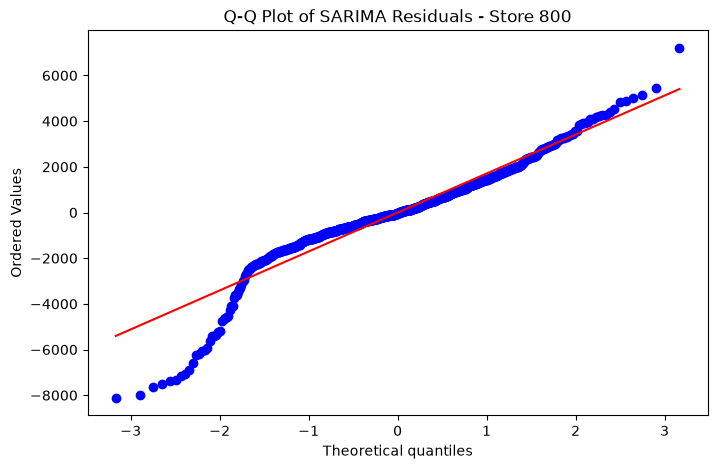

In [45]:
import matplotlib.pyplot as plt
import scipy.stats as stats

plt.figure(figsize=(8, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of SARIMA Residuals - Store 800")
plt.show()

### Rolling Origin-Backtesting

In [46]:
print("Sales observations:", len(sales))
print("Training observations:", len(train))
print("Test observations:", len(test))
print("Selected model:", model.order, model.seasonal_order)

Sales observations: 942
Training observations: 900
Test observations: 42
Selected model: (5, 1, 0) (2, 0, 0, 7)


### Back-Testing Setup

In [51]:
# Rolling-origin backtesting setup

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

backtest_series = sales.asfreq("D")

initial_train_size = 700
forecast_horizon = 7
step_size = 28

print("Total observations:", len(backtest_series))
print("Initial training size:", initial_train_size)
print("Forecast horizon:", forecast_horizon, "days")
print("Step between origins:", step_size, "days")

Total observations: 942
Initial training size: 700
Forecast horizon: 7 days
Step between origins: 28 days


In [71]:
# Rolling-origin backtesting

backtest_results = []

for start in range(
    initial_train_size,
    len(backtest_series) - forecast_horizon + 1,
    step_size
):
    train_window = backtest_series.iloc[:start]
    actual = backtest_series.iloc[start:start + forecast_horizon]

    bt_model = pm.ARIMA(
        order=(5, 1, 0),
        seasonal_order=(2, 0, 0, 7),
        with_intercept=False
    )

    bt_model.fit(train_window)
    predictions = bt_model.predict(n_periods=forecast_horizon)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    backtest_results.append({
        "Training_Observations": start,
        "Forecast_Start": actual.index[0],
        "Forecast_End": actual.index[-1],
        "MAE": mae,
        "RMSE": rmse
    })

backtest_df = pd.DataFrame(backtest_results)

print(backtest_df)

   Training_Observations Forecast_Start Forecast_End          MAE         RMSE
0                    700     2014-12-02   2014-12-08  1439.497708  1641.091196
1                    728     2014-12-30   2015-01-05  1518.580160  1778.025184
2                    756     2015-01-27   2015-02-02  1530.454535  1767.088397
3                    784     2015-02-24   2015-03-02   770.014432  1221.918318
4                    812     2015-03-24   2015-03-30   722.136408  1040.144906
5                    840     2015-04-21   2015-04-27   808.756183   903.498392
6                    868     2015-05-19   2015-05-25  1295.962669  1760.002046
7                    896     2015-06-16   2015-06-22  1213.314654  1600.288575
8                    924     2015-07-14   2015-07-20   683.824104   866.941191


In [72]:
# Rolling-origin backtesting for Seasonal Naive

seasonal_naive_results = []

for start in range(
    initial_train_size,
    len(backtest_series) - forecast_horizon + 1,
    step_size
):
    train_window = backtest_series.iloc[:start]
    actual = backtest_series.iloc[start:start + forecast_horizon]

    # Repeat the sales from the previous 7 days
    predictions = train_window.iloc[-7:].to_numpy()

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    seasonal_naive_results.append({
        "Training_Observations": start,
        "MAE": mae,
        "RMSE": rmse
    })

seasonal_naive_df = pd.DataFrame(seasonal_naive_results)

print(seasonal_naive_df)

   Training_Observations          MAE         RMSE
0                    700  1129.285714  1391.244099
1                    728  1611.142857  2338.019980
2                    756  1542.857143  1703.051295
3                    784  1360.428571  1795.091601
4                    812  1420.428571  1979.983009
5                    840  1390.857143  1629.993427
6                    868  2005.857143  3291.942870
7                    896  1408.428571  2084.854671
8                    924  1305.857143  1733.920207


In [73]:
comparison_df = pd.DataFrame({
    "Model": ["SARIMA", "Seasonal Naive"],
    "Average MAE": [
        backtest_df["MAE"].mean(),
        seasonal_naive_df["MAE"].mean()
    ],
    "Average RMSE": [
        backtest_df["RMSE"].mean(),
        seasonal_naive_df["RMSE"].mean()
    ]
})

print(comparison_df.round(2))

            Model  Average MAE  Average RMSE
0          SARIMA      1109.17       1397.67
1  Seasonal Naive      1463.90       1994.23


In [76]:
# Fit the selected SARIMA model using all Store 800 sales data

final_model = pm.ARIMA(
    order=(5, 1, 0),
    seasonal_order=(2, 0, 0, 7),
    with_intercept=False
)

final_model.fit(sales)

print(final_model.summary())

                                     SARIMAX Results                                     
Dep. Variable:                                 y   No. Observations:                  942
Model:             SARIMAX(5, 1, 0)x(2, 0, 0, 7)   Log Likelihood               -8352.267
Date:                           Thu, 15 Oct 2026   AIC                          16720.534
Time:                                   23:01:10   BIC                          16759.309
Sample:                               01-01-2013   HQIC                         16735.315
                                    - 07-31-2015                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7537      0.021    -35.522      0.000      -0.795      -0.712
ar.L2         -0.4346      0.034    -12.694

## Next 42 Days forecast

In [77]:
# Forecast the next 42 days using the final SARIMA model

final_forecast = final_model.predict(n_periods=42)

forecast_dates = pd.date_range(
    start=sales.index[-1] + pd.Timedelta(days=1),
    periods=42,
    freq="D"
)

final_forecast_series = pd.Series(
    final_forecast,
    index=forecast_dates,
    name="Forecast_Sales"
)

print(final_forecast_series)

2015-08-01    5210.552676
2015-08-02    1819.489074
2015-08-03    5606.176640
2015-08-04    4939.489591
2015-08-05    4840.585790
2015-08-06    5561.990566
2015-08-07    5437.479888
2015-08-08    5879.749769
2015-08-09    2184.982441
2015-08-10    6991.183025
2015-08-11    6016.276939
2015-08-12    5755.699382
2015-08-13    6704.454115
2015-08-14    6647.339194
2015-08-15    6269.699664
2015-08-16    3353.255884
2015-08-17    6784.302732
2015-08-18    6147.054148
2015-08-19    6023.681551
2015-08-20    6685.542243
2015-08-21    6598.201197
2015-08-22    6760.968299
2015-08-23    3862.771282
2015-08-24    7540.683261
2015-08-25    6809.579741
2015-08-26    6626.026957
2015-08-27    7348.146564
2015-08-28    7292.640883
2015-08-29    7113.298964
2015-08-30    4674.500118
2015-08-31    7611.685072
2015-09-01    7053.982827
2015-09-02    6935.358632
2015-09-03    7505.156641
2015-09-04    7440.054511
2015-09-05    7489.656146
2015-09-06    5178.026945
2015-09-07    8071.558161
2015-09-08  

In [81]:
# Check historical Sunday sales for Store 800

sunday_sales = sales[sales.index.dayofweek == 6]

print("Number of Sundays:", len(sunday_sales))
print("Non-zero Sunday sales:", (sunday_sales != 0).sum())
print("Average Sunday sales:", sunday_sales.mean())
print(sunday_sales.tail(10))

Number of Sundays: 134
Non-zero Sunday sales: 0
Average Sunday sales: 0.0
Date
2015-05-24    0
2015-05-31    0
2015-06-07    0
2015-06-14    0
2015-06-21    0
2015-06-28    0
2015-07-05    0
2015-07-12    0
2015-07-19    0
2015-07-26    0
Name: Sales, dtype: int64


### Sunday closure adjustment 

In [82]:
# Display the final adjusted forecast

print("Final 42-Day Forecast for Store 800")
print(adjusted_forecast.round(0).astype(int))

Final 42-Day Forecast for Store 800
2015-08-01    5211
2015-08-02       0
2015-08-03    5606
2015-08-04    4939
2015-08-05    4841
2015-08-06    5562
2015-08-07    5437
2015-08-08    5880
2015-08-09       0
2015-08-10    6991
2015-08-11    6016
2015-08-12    5756
2015-08-13    6704
2015-08-14    6647
2015-08-15    6270
2015-08-16       0
2015-08-17    6784
2015-08-18    6147
2015-08-19    6024
2015-08-20    6686
2015-08-21    6598
2015-08-22    6761
2015-08-23       0
2015-08-24    7541
2015-08-25    6810
2015-08-26    6626
2015-08-27    7348
2015-08-28    7293
2015-08-29    7113
2015-08-30       0
2015-08-31    7612
2015-09-01    7054
2015-09-02    6935
2015-09-03    7505
2015-09-04    7440
2015-09-05    7490
2015-09-06       0
2015-09-07    8072
2015-09-08    7503
2015-09-09    7366
2015-09-10    7932
2015-09-11    7883
Freq: D, Name: Forecast_Sales, dtype: int64


## Graph forcast

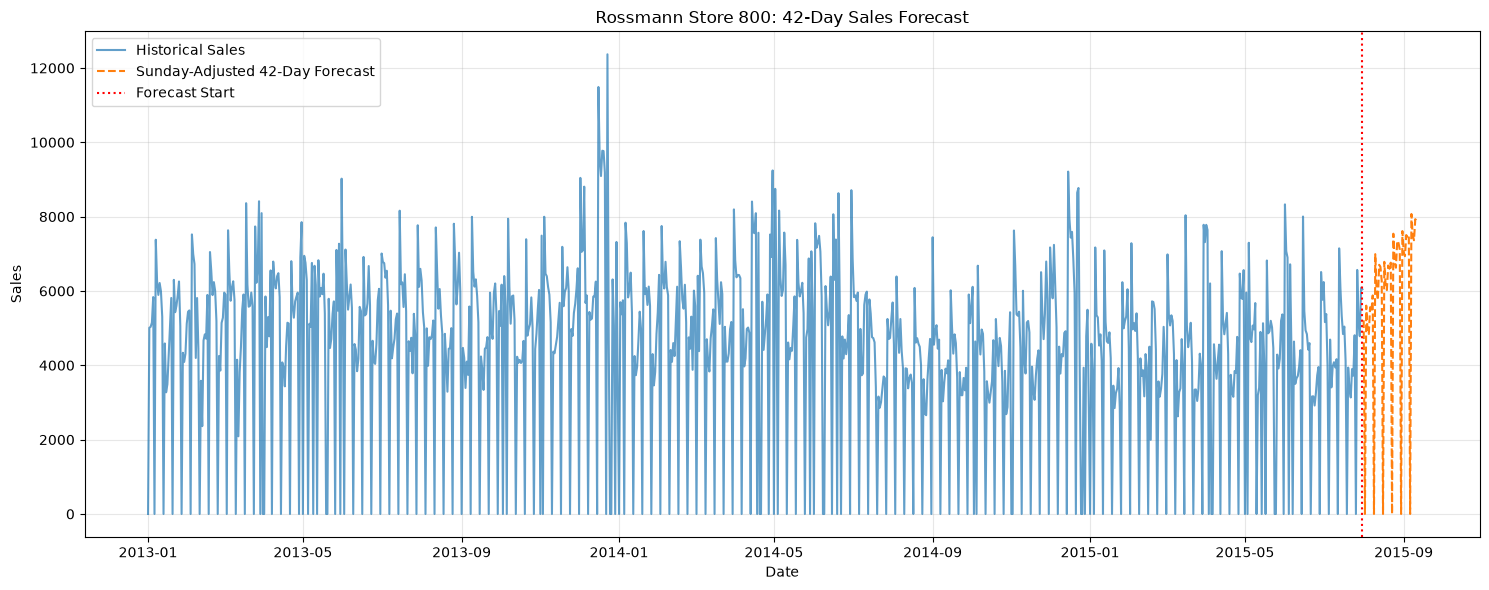

In [83]:

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    sales.index,
    sales,
    label="Historical Sales",
    alpha=0.7
)

plt.plot(
    adjusted_forecast.index,
    adjusted_forecast,
    label="Sunday-Adjusted 42-Day Forecast",
    linestyle="--"
)

plt.axvline(
    x=sales.index[-1],
    color="red",
    linestyle=":",
    label="Forecast Start"
)

plt.title("Rossmann Store 800: 42-Day Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Final Findings and Conclusion: Rossmann Store 800

## 1. Data Preparation and Exploration

We selected Store 800 and analysed 942 daily sales records from January 2013 to July 2015. There were no missing values in the selected data, and we set the date column as the daily time index.

From the analysis, we found that sales varied across the week. Monday had the highest average sales of about 5,832.57, while Sunday sales were zero because the store was closed. Sales were also higher on promotional days and during school holidays.

## 2. Stationarity and Model Selection

We used the ADF test to check stationarity. The p-value was 0.0033, which provided evidence that the training series was stationary. The ACF plot also showed a clear weekly pattern, with spikes at lags 7, 14, 21 and other weekly intervals.

Based on the model selection results, we chose SARIMA(5,1,0)(2,0,0,7) for forecasting.

## 3. Comparing the Forecasting Models

We used the first 900 observations for training and the final 42 days for testing. We compared SARIMA against Naive, Seasonal Naive, Moving Average and Drift.

Seasonal Naive recorded the lowest MAE of 1,004.83, while SARIMA had the lowest RMSE of 1,431.29. This means the simpler Seasonal Naive model performed better on average absolute error, while SARIMA performed better on RMSE.

The results show that the more complex model was not the best on every measure, so it is important to compare both models before making a decision.

## 4. Checking the Model Errors

We checked the SARIMA residuals using the ACF plot, Ljung–Box test and Q-Q plot. The results showed that some patterns remained in the errors, and the residuals did not follow a normal distribution closely.

This suggests that SARIMA did not capture every pattern in the sales data and that there is still room to improve the model.

## 5. Rolling-Origin Backtesting

We also tested the models across different periods using rolling-origin backtesting. We started with 700 observations, forecast the next seven days, and moved forward by 28 days before repeating the process. This gave us nine forecast windows.

SARIMA achieved an average MAE of 1,109.17 and RMSE of 1,397.67. Seasonal Naive recorded an average MAE of 1,463.90 and RMSE of 1,994.23.

SARIMA performed better across these backtesting windows. However, the original test covered 42 days, while each backtest covered seven days, so the results are not directly equivalent.

## 6. Final Six-Week Forecast

We fitted the final model using all 942 observations and forecast sales for the next 42 days, from 1 August to 11 September 2015.

The original model predicted positive sales for Sundays, but our historical data showed that the store recorded zero sales on those days. We therefore set the Sunday forecasts to zero and kept the predictions for the other days unchanged.

## 7. Could Poor Forecasting Be Costing Rossmann Money?

Poor forecasts can affect how much stock a store orders and how staff are scheduled. Overestimating sales could lead to excess stock or unnecessary staffing, while underestimating sales could result in stock shortages or not having enough staff during busy periods.

Our results show that forecast errors remain. On the original test period, SARIMA had an MAE of about 1,187 sales units per day, compared with 1,005 for Seasonal Naive.

However, we cannot calculate the actual money lost from these errors because we do not have information about stock costs, profit margins, staffing costs or lost sales. We can identify the possible business impact, but we cannot put a reliable financial figure on it from this analysis alone.

## 8. Recommendation

Based on our results, we would not recommend using SARIMA across all Rossmann stores yet. Although it performed better during rolling-origin backtesting, Seasonal Naive had a lower MAE on the original test period. The residual checks also showed that the SARIMA model could be improved.

We recommend testing both models on more stores and over different periods. We should also consider promotions, holidays and store closures when developing the next version.

If Seasonal Naive gives sufficiently accurate results, it may be the better choice because it is simpler to use and maintain. SARIMA should only be preferred where its performance offers a clear benefit.

## Conclusion

We found that Store 800's sales followed a weekly pattern and that promotions and holidays were associated with differences in average sales. SARIMA performed well in rolling-origin backtesting, but it did not outperform Seasonal Naive on every measure.

The analysis shows that better forecasting could support stock and staffing decisions, but more testing is needed before choosing a method for wider use. We would also need financial data to estimate how much better forecasting could save the business.